In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.api import OLS

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Define treatment dummy variables and add them back into dataset:

dataset["treatment"] = dataset["treatment"].astype(int)
treatment_dummies = pd.get_dummies(dataset['treatment'], prefix='treatment', dtype=int)
dataset = pd.concat([dataset, treatment_dummies], axis=1)

# Define variables for analysis:

variables = [
    "voted",
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2004",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

In [2]:
# Estimating ATE in Full Experimental Sample, Any Treatment:

# Defining Treatment:

dataset["D"] = dataset[
    ["treatment_1", "treatment_2", "treatment_3", "treatment_4"]
].max(axis=1)

# Defining Covariates:

covariates = [
    "hh_size", "g2004", "g2002", "g2000",
    "p2004", "p2002", "p2000", "sex", "yob"
]

# Selecting Variables for ATE Estimates:

df = dataset[["voted", "D", "hh_id"] + covariates].dropna().copy()

Y = df["voted"].to_numpy(dtype=float)
D = df["D"].to_numpy(dtype=float)

X = sm.add_constant(
    df[["D"] + covariates], has_constant="add"
).to_numpy(dtype=float)

#  Constructing full-sample estimates

ATE_means = Y[D == 1].mean() - Y[D == 0].mean()

ATE_OLS = np.linalg.lstsq(X, Y, rcond=None)[0][1]

# Constructing bootstrap confidence intervals

rng = np.random.default_rng(1465)
B = 300

households = df["hh_id"].unique()
household_indices = df.groupby("hh_id").indices

bootstrap_means = []
bootstrap_OLS = []

for b in range(B):

    sampled_households = rng.choice(
        households, size=len(households), replace=True
    )

    indices = np.concatenate(
        [household_indices[h] for h in sampled_households]
    )

    Y_b = Y[indices]
    D_b = D[indices]
    X_b = X[indices]

    means_b = Y_b[D_b == 1].mean() - Y_b[D_b == 0].mean()

    ols_b = np.linalg.lstsq(X_b, Y_b, rcond=None)[0][1]

    bootstrap_means.append(means_b)
    bootstrap_OLS.append(ols_b)

# Constructing percentile 95% confidence intervals

CI_means = np.percentile(bootstrap_means, [2.5, 97.5])
CI_OLS = np.percentile(bootstrap_OLS, [2.5, 97.5])

# Displaying results in percentage points

results = pd.DataFrame({
    "Estimator": ["Difference in Means", "Covariate-Adjusted OLS"],
    "ATE (pp)": [ATE_means * 100, ATE_OLS * 100],
    "95% CI Lower (pp)": [CI_means[0] * 100, CI_OLS[0] * 100],
    "95% CI Upper (pp)": [CI_means[1] * 100, CI_OLS[1] * 100]
})

print(results.round(3).to_string(index=False))

             Estimator  ATE (pp)  95% CI Lower (pp)  95% CI Upper (pp)
   Difference in Means     4.336              3.966              4.720
Covariate-Adjusted OLS     4.290              3.963              4.686


Recipe: B
Selection variable: yob
Alpha: 0.0
Gamma: 1.0
Seed: 1465
         Full Sample  Biased Sample
Total         344084         171990
Treated       152841          76196
Control       191243          95794
         Full Control  Full Treated  Biased Control  Biased Treated
yob          1956.186      1956.248        1950.238        1962.239
hh_size         2.184         2.184           2.092           2.280
g2002           0.811         0.812           0.860           0.762
p2004           0.400         0.403           0.410           0.396
sex             0.499         0.500           0.492           0.506


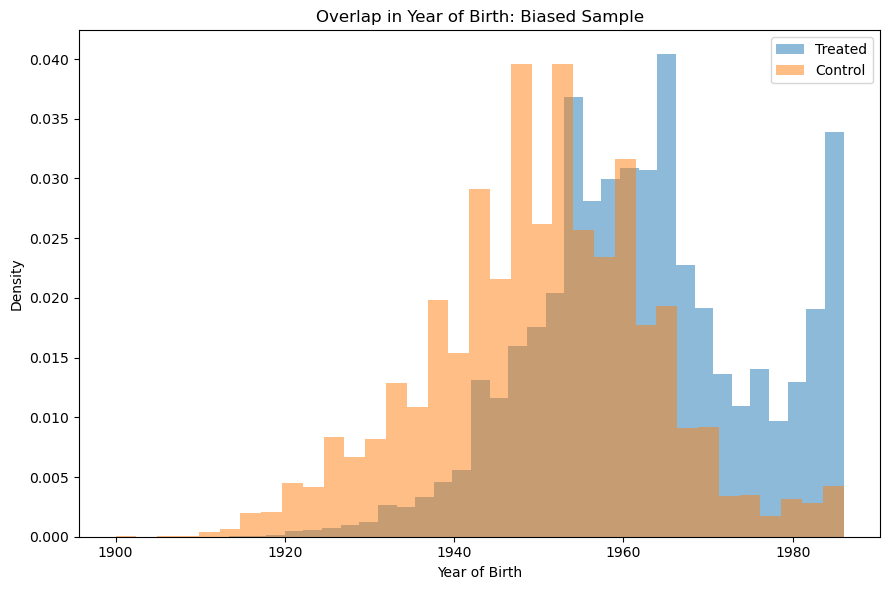

Full sample ATE: 4.336 pp
Biased sample naive ATE: -0.846 pp
Difference: -5.182 pp


In [3]:
from scipy.special import expit
import matplotlib.pyplot as plt

# Selection parameters
S = "yob"
alpha = 0.0
gamma = 1.0
seed = 1465

rng = np.random.default_rng(seed)

# Standardize selection variable
S_std = (df[S] - df[S].mean()) / df[S].std()

# Treated = +1, Control = -1
sign = np.where(df["D"] == 1, 1, -1)

# Logistic selection probability
u = alpha + gamma * sign * S_std
p_keep = expit(u)

# Select observations
keep = rng.uniform(size=len(df)) < p_keep
biased = df.loc[keep].copy()

print(f"Recipe: B")
print(f"Selection variable: {S}")
print(f"Alpha: {alpha}")
print(f"Gamma: {gamma}")
print(f"Seed: {seed}")

# Reporting sample sizes:

sample_sizes = pd.DataFrame({
    "Full Sample": [
        len(df),
        (df["D"] == 1).sum(),
        (df["D"] == 0).sum()
    ],
    "Biased Sample": [
        len(biased),
        (biased["D"] == 1).sum(),
        (biased["D"] == 0).sum()
    ]
}, index=["Total", "Treated", "Control"])

print(sample_sizes)

# Generating the balance table:

balance_vars = ["yob", "hh_size", "g2002", "p2004", "sex"]

full_balance = df.groupby("D")[balance_vars].mean().T
biased_balance = biased.groupby("D")[balance_vars].mean().T

balance_table = pd.DataFrame({
    "Full Control": full_balance[0],
    "Full Treated": full_balance[1],
    "Biased Control": biased_balance[0],
    "Biased Treated": biased_balance[1]
})

print(balance_table.round(3).to_string())

# Generating the overlap plot:

plt.figure(figsize=(9, 6))

plt.hist(
    biased.loc[biased["D"] == 1, S],
    bins=35,
    density=True,
    alpha=0.5,
    label="Treated"
)

plt.hist(
    biased.loc[biased["D"] == 0, S],
    bins=35,
    density=True,
    alpha=0.5,
    label="Control"
)

plt.xlabel("Year of Birth")
plt.ylabel("Density")
plt.title("Overlap in Year of Birth: Biased Sample")
plt.legend()
plt.tight_layout()
plt.show()


# Verifying that the sample creates bias:


# Difference in means in full sample
ATE_full = (
    df.loc[df["D"] == 1, "voted"].mean()
    - df.loc[df["D"] == 0, "voted"].mean()
)

# Naive difference in means in biased sample
ATE_biased = (
    biased.loc[biased["D"] == 1, "voted"].mean()
    - biased.loc[biased["D"] == 0, "voted"].mean()
)

print(f"Full sample ATE: {ATE_full * 100:.3f} pp")
print(f"Biased sample naive ATE: {ATE_biased * 100:.3f} pp")
print(f"Difference: {(ATE_biased - ATE_full) * 100:.3f} pp")


In [4]:
# The naive estimate on the biased sample


# 1. Naive difference in means (biased sample)

ATE_naive_means = (
    biased.loc[biased["D"] == 1, "voted"].mean()
    - biased.loc[biased["D"] == 0, "voted"].mean()
)

# 2. Naive OLS regression (without S = yob)

X_naive = sm.add_constant(biased[["D"]])
Y_naive = biased["voted"]

naive_model = sm.OLS(Y_naive, X_naive).fit()

ATE_naive_OLS = naive_model.params["D"]

# 3. Compare to RCT benchmark from full sample

comparison = pd.DataFrame({
    "Estimator": [
        "RCT Benchmark (Adjusted OLS)",
        "Naive Difference in Means",
        "Naive OLS"
    ],
    "ATE (percentage points)": [
        ATE_OLS * 100,
        ATE_naive_means * 100,
        ATE_naive_OLS * 100
    ]
})

print(comparison.round(3).to_string(index=False))

                   Estimator  ATE (percentage points)
RCT Benchmark (Adjusted OLS)                    4.290
   Naive Difference in Means                   -0.846
                   Naive OLS                   -0.846

Selecting on year of birth changes the estimated treatment effect from 4.29 to -0.85 percentage points.


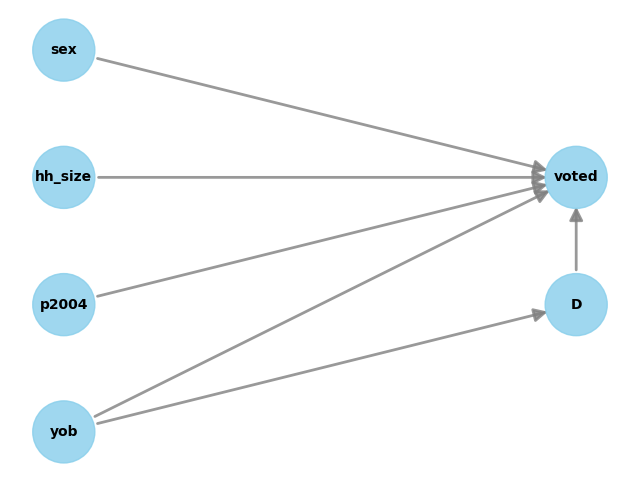

In [13]:
# Testing DAG 2 with data

from dowhy import CausalModel
import graphviz

# Define the DAG in GML format
gml_graph = """
graph [
    directed 1

    node [id "D" label "D"]
    node [id "voted" label "voted"]
    node [id "yob" label "yob"]
    node [id "sex" label "sex"]
    node [id "hh_size" label "hh_size"]
    node [id "p2004" label "p2004"]

    edge [source "yob" target "D"]
    edge [source "yob" target "voted"]
    edge [source "D" target "voted"]

    edge [source "sex" target "voted"]
    edge [source "hh_size" target "voted"]
    edge [source "p2004" target "voted"]
]
"""

# Step 1: Instantiate the causal model
model = CausalModel(
    data=biased,
    treatment="D",
    outcome="voted",
    graph=gml_graph
)

print(model)
model.view_model()

In [7]:
# Step 2: Identify the causal estimand

estimand = model.identify_effect()

print(estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
 d                
────(E[voted|yob])
d[D]              
Estimand assumption 1, Unconfoundedness: If U→{D} and U→voted then P(voted|D,yob,U) = P(voted|D,yob)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
 d                
────(E[voted|yob])
d[D]              
Estimand assumption 1, Unconfoundedness: If U→{D} and U→voted then P(voted|D,yob,U) = P(voted|D,yob)



In [8]:
# Step 3: Estimate the treatment effect

estimate = model.estimate_effect(
    identified_estimand=estimand,
    method_name="backdoor.linear_regression"
)

print(estimate.value)

# Compare with previous estimates

print(f"RCT benchmark: {ATE_OLS * 100:.3f} pp")
print(f"Naive estimate: {ATE_naive_OLS * 100:.3f} pp")
print(f"DoWhy estimate: {estimate.value * 100:.3f} pp")

0.04060228553426842
RCT benchmark: 4.290 pp
Naive estimate: -0.846 pp
DoWhy estimate: 4.060 pp


C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\causal_estimator.py:272: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  conditional_estimates = by_effect_mods.apply(estimate_effect_fn)


In [9]:
# Step 4A: Random common cause

refute_cc = model.refute_estimate(
    estimand=estimand,
    estimate=estimate,
    method_name="random_common_cause",
    random_state=1465
)

print("Random Common Cause Refutation:")
print(refute_cc)

# Step 4B: Data subset refuter

refute_subset = model.refute_estimate(
    estimand=estimand,
    estimate=estimate,
    method_name="data_subset_refuter",
    subset_fraction=0.4,
    random_state=1465
)

print("\nData Subset Refutation:")
print(refute_subset)

C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\causal_estimator.py:272: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  conditional_estimates = by_effect_mods.apply(estimate_effect_fn)
C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\causal_estimator.py:272: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  conditional_estimates = by_effect_mods.apply(estimate_effect_fn)
C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\c

Random Common Cause Refutation:
Refute: Add a random common cause
Estimated effect:0.04060228553426842
New effect:0.04060251118843669
p value:0.8400000000000001



C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\causal_estimator.py:272: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  conditional_estimates = by_effect_mods.apply(estimate_effect_fn)
C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\causal_estimator.py:272: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  conditional_estimates = by_effect_mods.apply(estimate_effect_fn)
C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\c


Data Subset Refutation:
Refute: Use a subset of data
Estimated effect:0.04060228553426842
New effect:0.041107815168283
p value:0.0



C:\Users\jonat\anaconda3\Lib\site-packages\dowhy\causal_estimator.py:272: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  conditional_estimates = by_effect_mods.apply(estimate_effect_fn)
